# **Operaciones de aprendizaje automático**

## Maestría en Inteligencia Artificial Aplicada
#### Tecnológico de Monterrey

### **Proyecto MiBici | Exploración de datos (EDA) | Equipo 04**

* **Autor:** David Alonso Cantú Martínez

> Notebook de **exploración de datos (EDA)** de los viajes de [MiBici](https://www.mibici.net/es/datos-abiertos/) (enero a junio de 2026). La lógica de limpieza vive en `mibici_mlops_module/dataset.py` y la de variables y partición en `mibici_mlops_module/features.py`. Este notebook solo lee sus resultados y los explora. El entrenamiento y el registro en MLflow viven en `modeling/train.py`.

| Pregunta | Tabla | Una fila es | Objetivo |
| --- | --- | --- | --- |
| P1. Demanda | `p1_demanda.parquet` | estación × hora t | salidas en t+1 |
| P2. Riesgo | `p2_riesgo.parquet` | estación × hora t | clase de riesgo en t+1 (vaciado, normal, saturación) |
| P3. Tipología | `p3_perfiles.parquet` | estación | sin objetivo (clustering) |

**Antes de correrlo**, genera las tablas desde la raíz del proyecto (descarga los CSV a `data/raw/`):

```bash
python -m mibici_mlops_module.dataset   # descarga, normaliza, limpia y versiona (data/manifest.json)
python -m mibici_mlops_module.features  # data/interim -> data/processed
```

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from mibici_mlops_module.config import (
    FIN_ENTRENAMIENTO,
    FIN_VALIDACION,
    INTERIM_DATA_DIR,
    PROCESSED_DATA_DIR,
    U_RIESGO,
)

sns.set_theme(style="whitegrid", palette="Set2")
DIAS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
ORDEN_CONJUNTO = ["entrenamiento", "validacion", "prueba"]
ORDEN_RIESGO = ["vaciado", "normal", "saturacion"]

2026-10-14 15:47:59.632 | INFO     | mibici_mlops_module.config:<module>:12 - PROJ_ROOT path is: /home/davidc/Posgrado/MLops/TC5061-Proyecto-Equipo04


### Paso 1: Carga y descripción de los datos

In [2]:
viajes = pd.read_parquet(INTERIM_DATA_DIR / "viajes_limpios.parquet")
cat = pd.read_parquet(INTERIM_DATA_DIR / "nomenclatura.parquet")
p1 = pd.read_parquet(PROCESSED_DATA_DIR / "p1_demanda.parquet")
p2 = pd.read_parquet(PROCESSED_DATA_DIR / "p2_riesgo.parquet")
p3 = pd.read_parquet(PROCESSED_DATA_DIR / "p3_perfiles.parquet")
resumen = json.loads((PROCESSED_DATA_DIR / "resumen.json").read_text(encoding="utf-8"))

viajes["duracion_min"] = (viajes["fin_viaje"] - viajes["inicio_viaje"]).dt.total_seconds() / 60
print(f"Versión de los datos: {resumen['data_version']}")
print(f"Viajes limpios: {len(viajes):,}")
print(f"Estaciones en la nomenclatura: {len(cat)}")
print(f"Filas P1 y P2: {len(p1):,} ({p1['estacion'].nunique()} estaciones)")
print(f"Estaciones con perfil (P3): {len(p3)}")
display(viajes.dtypes.to_frame("Tipo"))

Versión de los datos: bd6802fef84e
Viajes limpios: 2,012,763
Estaciones en la nomenclatura: 484
Filas P1 y P2: 1,552,848 (411 estaciones)
Estaciones con perfil (P3): 369


,Tipo
viaje_id,int32
inicio_viaje,datetime64[us]
fin_viaje,datetime64[us]
origen_id,int32
destino_id,int32
duracion_min,float64


Las columnas personales (`Usuario_Id`, `Genero`, `Año_de_nacimiento`) **nunca se cargan**, por minimización de datos personales. Los viajes solo conservan identificador, fechas y estaciones de origen y destino.

### Paso 2: Análisis exploratorio (EDA)

#### 2.1 Calidad de los datos y limpieza

In [3]:
limpieza = pd.Series({
    "Viajes crudos": resumen["viajes_crudos"],
    "Duplicados": resumen["duplicados"],
    "Nulos": resumen["nulos"],
    "Menos de 1 minuto": resumen["menos_1_min"],
    "Más de 3 horas": resumen["mas_180_min"],
    "De estaciones fuera de la nomenclatura": resumen["viajes_estaciones_fuera"],
    "Viajes limpios": resumen["viajes_limpios"],
}, name="Viajes").to_frame()
limpieza["% de los crudos"] = (limpieza["Viajes"] / resumen["viajes_crudos"] * 100).round(2)
display(limpieza)
print("Estaciones fuera de la nomenclatura:", resumen["estaciones_fuera_catalogo"])

nulos = pd.DataFrame({
    "P1": p1.isna().sum().sum(), "P2": p2.isna().sum().sum(), "P3": p3.isna().sum().sum(),
}, index=["Nulos totales"])
display(nulos)

,Viajes,% de los crudos
Viajes crudos,2090228,100.00
Duplicados,0,0.00
Nulos,0,0.00
Menos de 1 minuto,75295,3.60
Más de 3 horas,249,0.01
De estaciones fuera de la nomenclatura,1921,0.09
Viajes limpios,2012763,96.29


Estaciones fuera de la nomenclatura: [405, 407]


,P1,P2,P3
Nulos totales,0,0,0


Los viajes de menos de 1 minuto son sobre todo anclajes fallidos (origen igual a destino). Las estaciones 405 y 407 no están en la nomenclatura, así que no se puede conocer su capacidad y se excluyen.

#### 2.2 Viajes en el tiempo

,viajes
inicio_viaje,
2026-01,346608
2026-02,319019
2026-03,364780
2026-04,341686
2026-05,305081
2026-06,335589


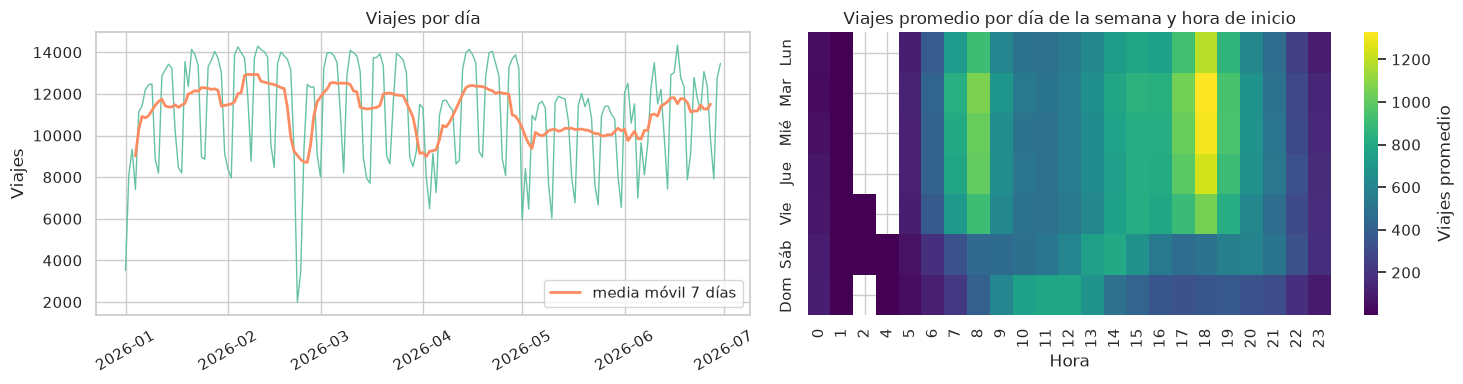

In [4]:
mes = viajes["inicio_viaje"].dt.to_period("M").astype(str)
por_mes = viajes.groupby(mes).size().rename("viajes")
display(por_mes.to_frame())

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
por_dia = viajes.groupby(viajes["inicio_viaje"].dt.normalize()).size()
axes[0].plot(por_dia.index, por_dia.values, lw=1)
axes[0].plot(por_dia.rolling(7, center=True).mean(), lw=2, label="media móvil 7 días")
axes[0].set(title="Viajes por día", ylabel="Viajes")
axes[0].legend()
axes[0].tick_params(axis="x", rotation=30)

hora = viajes["inicio_viaje"].dt.hour
dow = viajes["inicio_viaje"].dt.dayofweek
heat = viajes.groupby([dow, hora]).size().unstack().div(viajes["inicio_viaje"].dt.normalize().nunique() / 7)
sns.heatmap(heat, cmap="viridis", yticklabels=DIAS, ax=axes[1], cbar_kws={"label": "Viajes promedio"})
axes[1].set(title="Viajes promedio por día de la semana y hora de inicio", xlabel="Hora", ylabel="")
plt.tight_layout()
plt.show()

Se espera ver dos picos entre semana (entrada y salida del trabajo y la escuela) y un patrón más plano y tardío en fin de semana. Esto justifica incluir `hora`, `dia_semana` y `es_fin_de_semana` como variables.

#### 2.3 Duración de los viajes

,minutos
count,2012763.00
mean,11.52
std,7.51
min,1.00
5%,3.02
25%,6.07
50%,9.85
75%,15.37
95%,24.95
99%,34.17


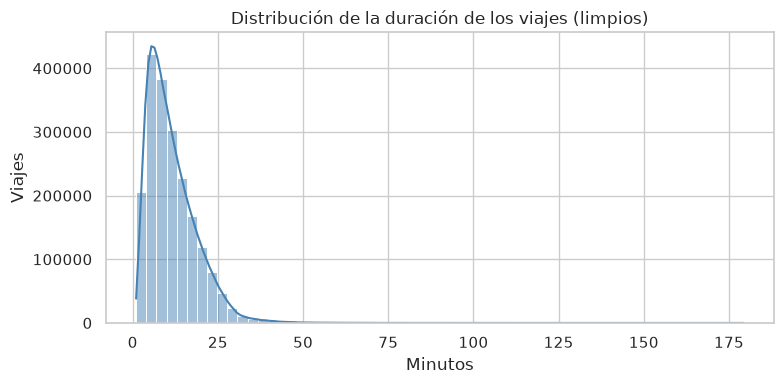

In [5]:
display(viajes["duracion_min"].describe(percentiles=[.05, .25, .5, .75, .95, .99]).round(2).to_frame("minutos"))

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(viajes["duracion_min"], bins=60, kde=True, ax=ax, color="steelblue")
ax.set(title="Distribución de la duración de los viajes (limpios)", xlabel="Minutos", ylabel="Viajes")
plt.tight_layout()
plt.show()

#### 2.4 Estaciones: capacidad, ubicación y uso

,dpcapacity (anclajes)
count,426.00
mean,17.04
std,3.97
min,11.00
25%,15.00
50%,15.00
75%,19.00
max,39.00


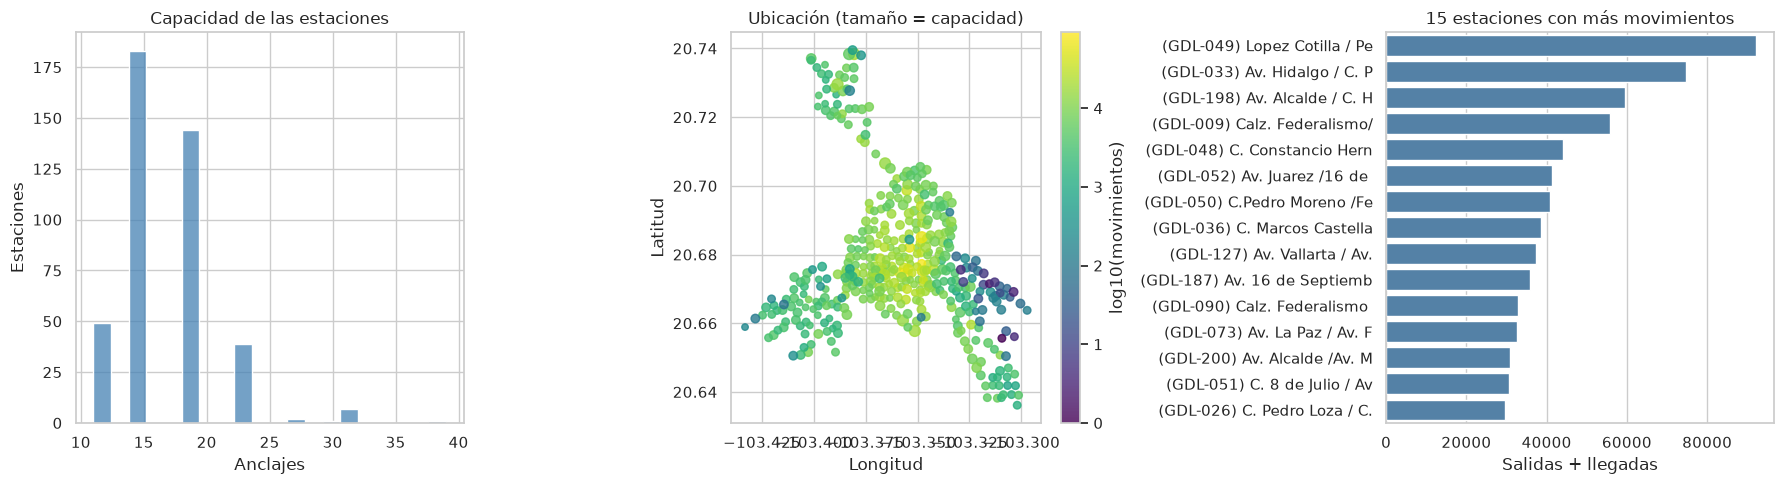

El 20 % de las estaciones concentra el 52.1% de los movimientos.


In [6]:
uso = (viajes.groupby("origen_id").size().rename("salidas").to_frame()
       .join(viajes.groupby("destino_id").size().rename("llegadas"), how="outer").fillna(0))
est = cat.set_index("estacion_id").join(uso).fillna({"salidas": 0, "llegadas": 0})
est["movimientos"] = est["salidas"] + est["llegadas"]
est_activas = est[est["movimientos"] > 0]
display(est_activas["capacidad"].describe().round(2).to_frame("dpcapacity (anclajes)"))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(est_activas["capacidad"], bins=20, ax=axes[0], color="steelblue")
axes[0].set(title="Capacidad de las estaciones", xlabel="Anclajes", ylabel="Estaciones")

sc = axes[1].scatter(est_activas["longitud"], est_activas["latitud"], c=np.log10(est_activas["movimientos"]),
                     s=est_activas["capacidad"] * 2, cmap="viridis", alpha=0.8)
plt.colorbar(sc, ax=axes[1], label="log10(movimientos)")
axes[1].set(title="Ubicación (tamaño = capacidad)", xlabel="Longitud", ylabel="Latitud")

top = est_activas.nlargest(15, "movimientos")
sns.barplot(x=top["movimientos"], y=top["nombre"].str[:28], color="steelblue", ax=axes[2])
axes[2].set(title="15 estaciones con más movimientos", xlabel="Salidas + llegadas", ylabel="")
plt.tight_layout()
plt.show()

conc = est_activas["movimientos"].sort_values(ascending=False)
print(f"El 20 % de las estaciones concentra el {conc.head(int(len(conc) * 0.2)).sum() / conc.sum():.1%} de los movimientos.")

#### 2.5 La red creció durante el semestre

Si una estación abre en mayo y se rellenan con 0 sus horas anteriores, el modelo aprendería "demanda cero" en una estación que no existía. Por eso cada estación tiene una **ventana de operación**: del día de su primer movimiento al día del último.

,Estaciones que abren
primer,
2026-03,1
2026-05,12
2026-06,45


Estaciones con movimiento todo el semestre (desde el 7 ene): 368
Estaciones que dejaron de registrar viajes antes del 24 jun:


,primer,ultimo,estacion_nombre
estacion,,,
34,2026-01-01,2026-05-24,(GDL-032) C. Degollado / Av. Miguel Hidalgo
35,2026-01-01,2026-06-11,(GDL-033) Av. Hidalgo / C. Pedro Loza


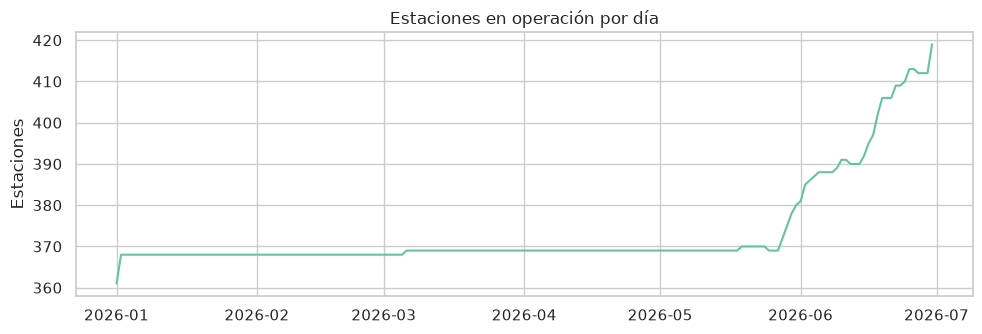

In [7]:
mov = pd.concat([
    viajes[["origen_id", "inicio_viaje"]].set_axis(["estacion", "t"], axis=1),
    viajes[["destino_id", "fin_viaje"]].set_axis(["estacion", "t"], axis=1),
])
ventana = mov.groupby("estacion")["t"].agg(primer="min", ultimo="max")
ventana["primer"] = ventana["primer"].dt.normalize()
ventana["ultimo"] = ventana["ultimo"].dt.normalize()

nuevas = ventana[ventana["primer"] > "2026-01-07"]
cerradas = ventana[ventana["ultimo"] < "2026-06-24"]
display(nuevas["primer"].dt.to_period("M").astype(str).value_counts().sort_index().to_frame("Estaciones que abren"))
print(f"Estaciones con movimiento todo el semestre (desde el 7 ene): {len(ventana) - len(nuevas)}")
print("Estaciones que dejaron de registrar viajes antes del 24 jun:")
display(cerradas.assign(estacion_nombre=cat.set_index("estacion_id").loc[cerradas.index, "nombre"]))

fig, ax = plt.subplots(figsize=(10, 3.5))
activas = pd.Series({d: ((ventana["primer"] <= d) & (ventana["ultimo"] >= d)).sum()
                     for d in pd.date_range("2026-01-01", "2026-06-30")})
ax.plot(activas.index, activas.values)
ax.set(title="Estaciones en operación por día", ylabel="Estaciones")
plt.tight_layout()
plt.show()

### Paso 3: P1. Demanda (salidas en t+1)

#### 3.1 Estructura de la tabla y partición temporal

In [8]:
print(f"Filas: {len(p1):,} | Variables: {p1.shape[1]}")
display(p1.groupby("conjunto").agg(
    filas=("estacion", "size"), estaciones=("estacion", "nunique"),
    desde=("hora_objetivo", "min"), hasta=("hora_objetivo", "max"),
).loc[ORDEN_CONJUNTO])
display(p1.describe().T.round(3))

Filas: 1,552,848 | Variables: 17


,filas,estaciones,desde,hasta
conjunto,,,,
entrenamiento,999024,369,2026-01-08,2026-04-30 23:00:00
validacion,274512,370,2026-05-01,2026-05-31 23:00:00
prueba,279312,410,2026-06-01,2026-06-30 23:00:00


,count,mean,min,25%,50%,75%,max,std
estacion,1552848.0,206.221709,2.0,101.0,207.0,311.0,503.0,118.346527
hora_t,1552848,2026-04-05 16:08:58.759232,2026-01-07 23:00:00,2026-02-20 22:00:00,2026-04-05 19:00:00,2026-05-19 15:00:00,2026-06-30 22:00:00,NaN
hora_objetivo,1552848,2026-04-05 17:08:58.759232,2026-01-08 00:00:00,2026-02-20 23:00:00,2026-04-05 20:00:00,2026-05-19 16:00:00,2026-06-30 23:00:00,NaN
hora,1552848.0,11.5,0.0,5.75,11.5,17.25,23.0,6.922189
dia_semana,1552848.0,3.005224,0.0,1.0,3.0,5.0,6.0,2.004802
es_fin_de_semana,1552848.0,0.287395,0.0,0.0,0.0,1.0,1.0,0.452547
es_festivo,1552848.0,0.017094,0.0,0.0,0.0,0.0,1.0,0.129621
es_semana_santa,1552848.0,0.068437,0.0,0.0,0.0,0.0,1.0,0.252494
latitud,1552848.0,20.67935,20.63613,20.666216,20.674931,20.689576,20.739523,0.021709
longitud,1552848.0,-103.362761,-103.433215,-103.383085,-103.362331,-103.344978,-103.297112,0.02719


La partición es **temporal por hora objetivo (t+1)**: entrenamiento hasta abril, validación en mayo y prueba en junio. Un muestreo aleatorio mezclaría el futuro con el pasado y daría métricas optimistas.

#### 3.2 Distribución del objetivo `y_salidas_t1`

,media,mediana,varianza,asimetría,% de ceros,máximo
y_salidas_t1,1.254,0.0,5.655,6.046,54.766,147


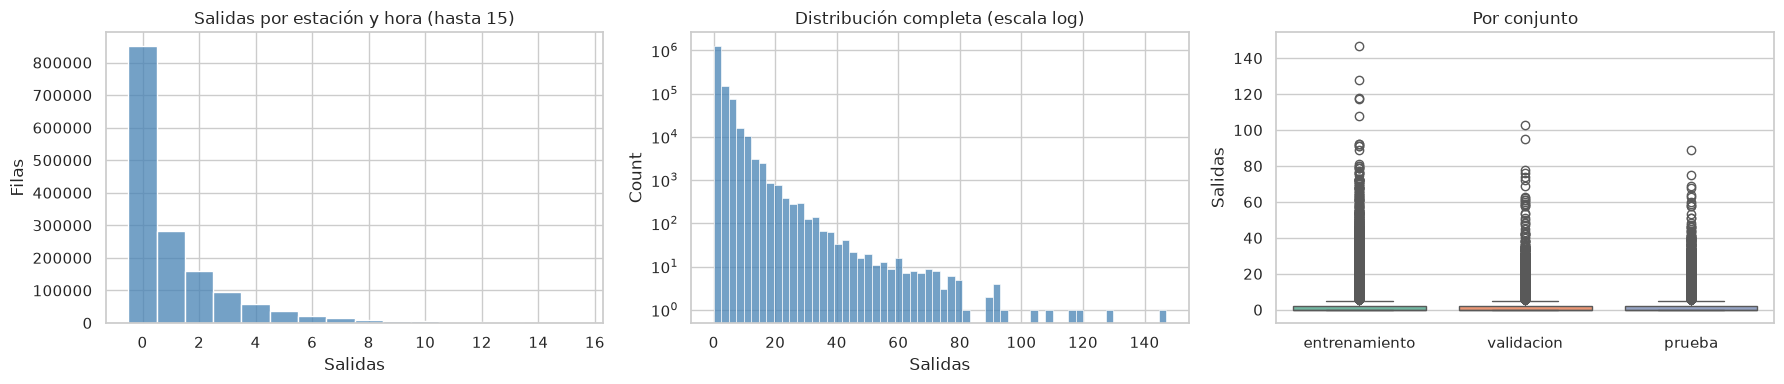

In [9]:
y = p1["y_salidas_t1"]
display(pd.DataFrame({
    "media": y.mean(), "mediana": y.median(), "varianza": y.var(), "asimetría": y.skew(),
    "% de ceros": (y == 0).mean() * 100, "máximo": y.max(),
}, index=["y_salidas_t1"]).round(3))

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.histplot(y[y <= 15], discrete=True, ax=axes[0], color="steelblue")
axes[0].set(title="Salidas por estación y hora (hasta 15)", xlabel="Salidas", ylabel="Filas")
axes[1].set_yscale("log")
sns.histplot(y, bins=60, ax=axes[1], color="steelblue")
axes[1].set(title="Distribución completa (escala log)", xlabel="Salidas")
sns.boxplot(data=p1, x="conjunto", y="y_salidas_t1", order=ORDEN_CONJUNTO, hue="conjunto", legend=False, ax=axes[2])
axes[2].set(title="Por conjunto", xlabel="", ylabel="Salidas")
plt.tight_layout()
plt.show()

El objetivo es un **conteo** con muchos ceros y cola larga, y con varianza mayor que la media (sobredispersión). Por eso la propuesta usa `HistGradientBoosting` con pérdida de Poisson y reporta MAE y RMSE.

#### 3.3 Patrón horario y por día de la semana

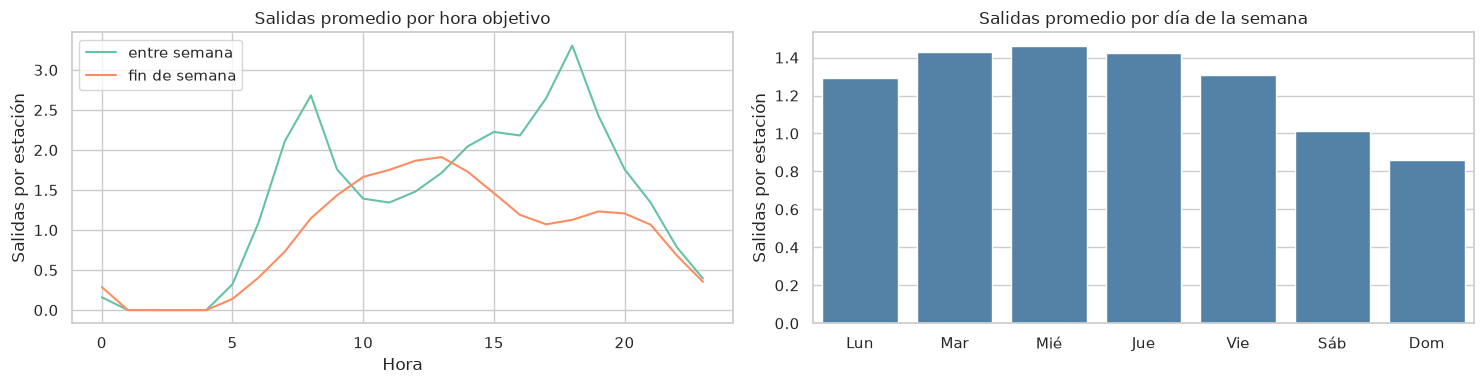

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.lineplot(data=p1, x="hora", y="y_salidas_t1", hue=p1["es_fin_de_semana"].map({0: "entre semana", 1: "fin de semana"}),
             errorbar=None, ax=axes[0])
axes[0].set(title="Salidas promedio por hora objetivo", xlabel="Hora", ylabel="Salidas por estación")
axes[0].legend(title="")
sns.barplot(data=p1, x="dia_semana", y="y_salidas_t1", errorbar=None, color="steelblue", ax=axes[1])
axes[1].set_xticks(range(7), DIAS)
axes[1].set(title="Salidas promedio por día de la semana", xlabel="", ylabel="Salidas por estación")
plt.tight_layout()
plt.show()

#### 3.4 Correlación de las variables con el objetivo

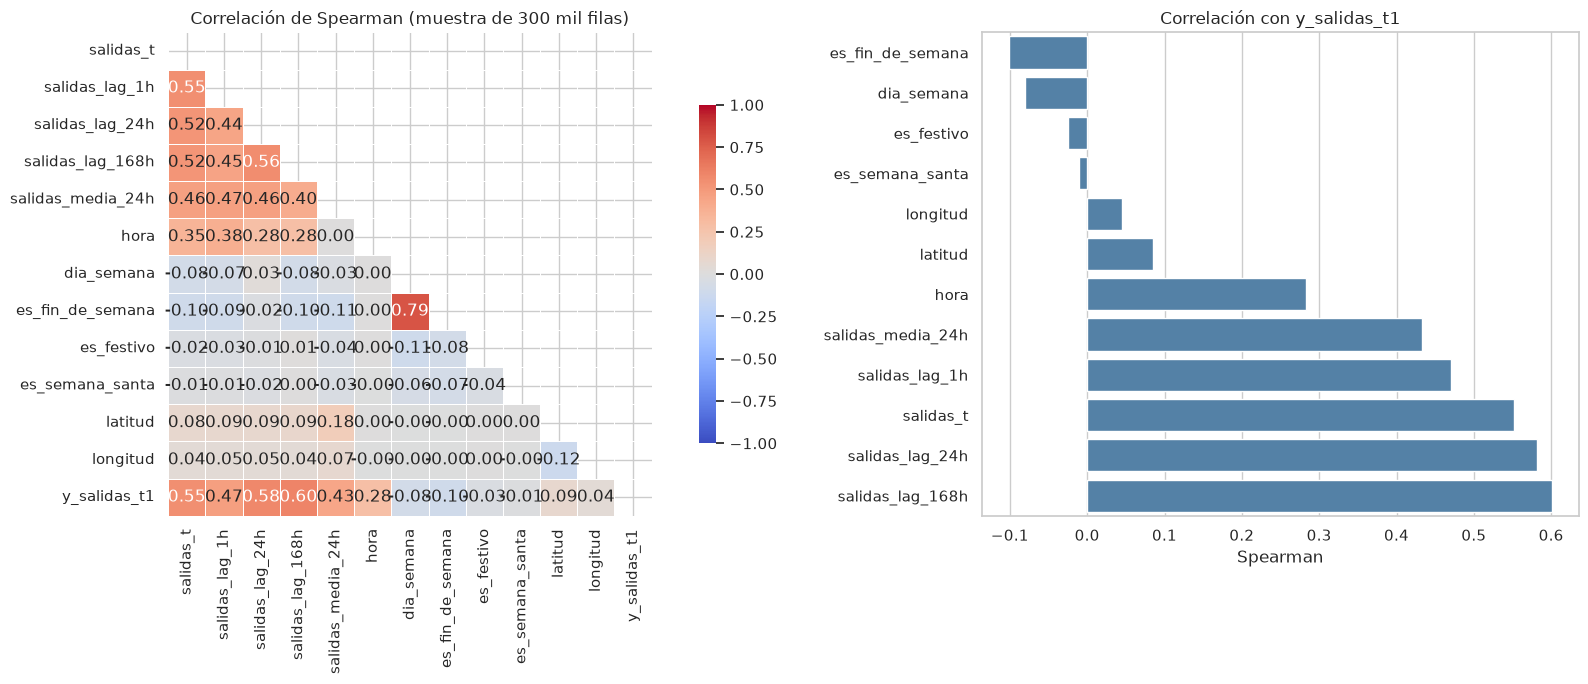

In [11]:
num = ["salidas_t", "salidas_lag_1h", "salidas_lag_24h", "salidas_lag_168h", "salidas_media_24h",
       "hora", "dia_semana", "es_fin_de_semana", "es_festivo", "es_semana_santa", "latitud", "longitud", "y_salidas_t1"]
corr = p1[num].sample(300_000, random_state=0).corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(18, 7), gridspec_kw={"width_ratios": [1.6, 1]})
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.7}, ax=axes[0])
axes[0].set_title("Correlación de Spearman (muestra de 300 mil filas)")
c = corr["y_salidas_t1"].drop("y_salidas_t1").sort_values()
sns.barplot(x=c.values, y=c.index, color="steelblue", ax=axes[1])
axes[1].set(title="Correlación con y_salidas_t1", xlabel="Spearman", ylabel="")
plt.tight_layout()
plt.show()

#### 3.5 Baselines de referencia

Antes de entrenar, se mide qué tan bien lo hacen reglas sin aprendizaje. Cualquier modelo debe superarlas en **validación**.

In [12]:
def metricas(real, pred):
    return {"MAE": np.abs(real - pred).mean(), "RMSE": np.sqrt(((real - pred) ** 2).mean())}

val = p1[p1["conjunto"] == "validacion"]
filas = {
    "Persistencia (salidas en t)": metricas(val["y_salidas_t1"], val["salidas_t"]),
    "Estacional diaria (t-23)": metricas(val["y_salidas_t1"], val["salidas_lag_24h"]),
    "Estacional semanal (t-167)": metricas(val["y_salidas_t1"], val["salidas_lag_168h"]),
    "Media de las últimas 24 h": metricas(val["y_salidas_t1"], val["salidas_media_24h"]),
    "Media global de entrenamiento": metricas(val["y_salidas_t1"], p1.loc[p1["conjunto"] == "entrenamiento", "y_salidas_t1"].mean()),
}
display(pd.DataFrame(filas).T.round(3).sort_values("MAE"))

,MAE,RMSE
Estacional semanal (t-167),0.891,1.759
Estacional diaria (t-23),0.938,1.862
Persistencia (salidas en t),0.969,1.803
Media de las últimas 24 h,1.092,1.821
Media global de entrenamiento,1.390,2.115


### Paso 4: P2. Riesgo de vaciado o saturación

El índice de flujo es **(llegadas − salidas) / capacidad** en la hora t+1. Se clasifica como **vaciado** si es ≤ −u, **saturación** si es ≥ +u y **normal** en otro caso, con u = 0.20 (un cambio neto del 20 % de los anclajes en una hora).

#### 4.1 Distribución del índice y elección del umbral

,indice_flujo_t1 (entrenamiento)
count,999024.000
mean,-0.001
std,0.103
min,-4.632
0.1%,-0.533
2.5%,-0.200
50%,0.000
97.5%,0.211
99.9%,0.600
max,1.600


Percentil 2.5 = -0.200 | Percentil 97.5 = 0.211 | u = ±0.2


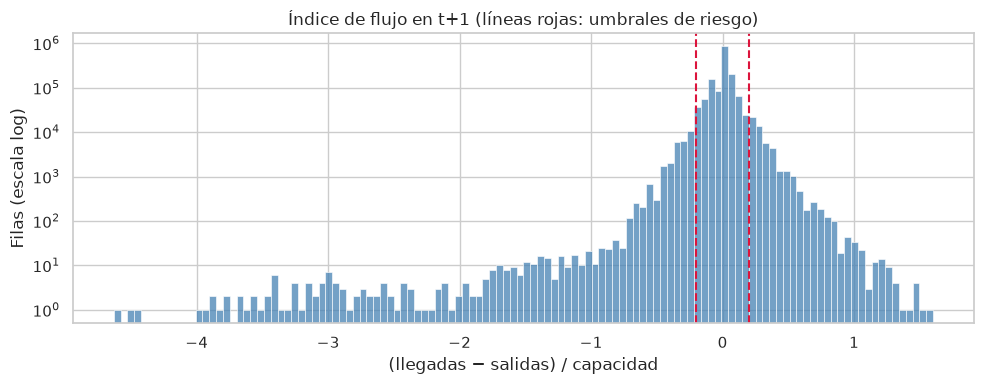

In [13]:
idx = p2["indice_flujo_t1"]
entr = p2.loc[p2["conjunto"] == "entrenamiento", "indice_flujo_t1"]
display(entr.describe(percentiles=[.001, .025, .5, .975, .999]).round(3).to_frame("indice_flujo_t1 (entrenamiento)"))
print(f"Percentil 2.5 = {entr.quantile(0.025):.3f} | Percentil 97.5 = {entr.quantile(0.975):.3f} | u = ±{U_RIESGO}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.set_yscale("log")
sns.histplot(idx, bins=120, ax=ax, color="steelblue")
for s in (-U_RIESGO, U_RIESGO):
    ax.axvline(s, color="crimson", ls="--")
ax.set(title="Índice de flujo en t+1 (líneas rojas: umbrales de riesgo)", xlabel="(llegadas − salidas) / capacidad", ylabel="Filas (escala log)")
plt.tight_layout()
plt.show()

#### 4.2 Desbalance de clases por conjunto

y_riesgo_t1,vaciado,normal,saturacion
conjunto,,,
entrenamiento,3.49,93.01,3.51
validacion,2.86,94.23,2.91
prueba,2.76,94.41,2.83


y_riesgo_t1,vaciado,normal,saturacion
conjunto,,,
entrenamiento,34824,929172,35028
validacion,7850,258660,8002
prueba,7717,263690,7905


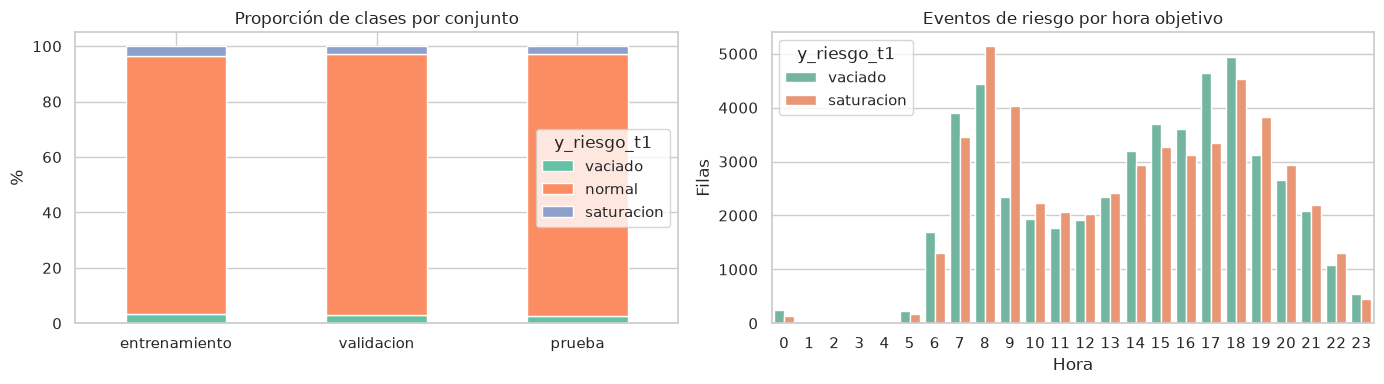

In [14]:
prop = (p2.groupby("conjunto")["y_riesgo_t1"].value_counts(normalize=True).mul(100).round(2)
        .unstack()[ORDEN_RIESGO].loc[ORDEN_CONJUNTO])
display(prop)
conteo = p2.groupby(["conjunto", "y_riesgo_t1"]).size().unstack()[ORDEN_RIESGO].loc[ORDEN_CONJUNTO]
display(conteo)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
prop.plot(kind="bar", stacked=True, ax=axes[0], rot=0)
axes[0].set(title="Proporción de clases por conjunto", ylabel="%", xlabel="")
sns.countplot(data=p2, x="hora", hue="y_riesgo_t1", hue_order=["vaciado", "saturacion"],
              ax=axes[1], order=range(24))
axes[1].set(title="Eventos de riesgo por hora objetivo", xlabel="Hora", ylabel="Filas")
plt.tight_layout()
plt.show()

Las clases de riesgo son raras (alrededor del 3 % cada una) y su proporción **cambia entre conjuntos**. Con ese desbalance la exactitud (*accuracy*) engaña: predecir siempre "normal" ya da más de 93 %. Por eso las métricas son recall por clase, balanced accuracy y F1 macro.

#### 4.3 Riesgo por estación

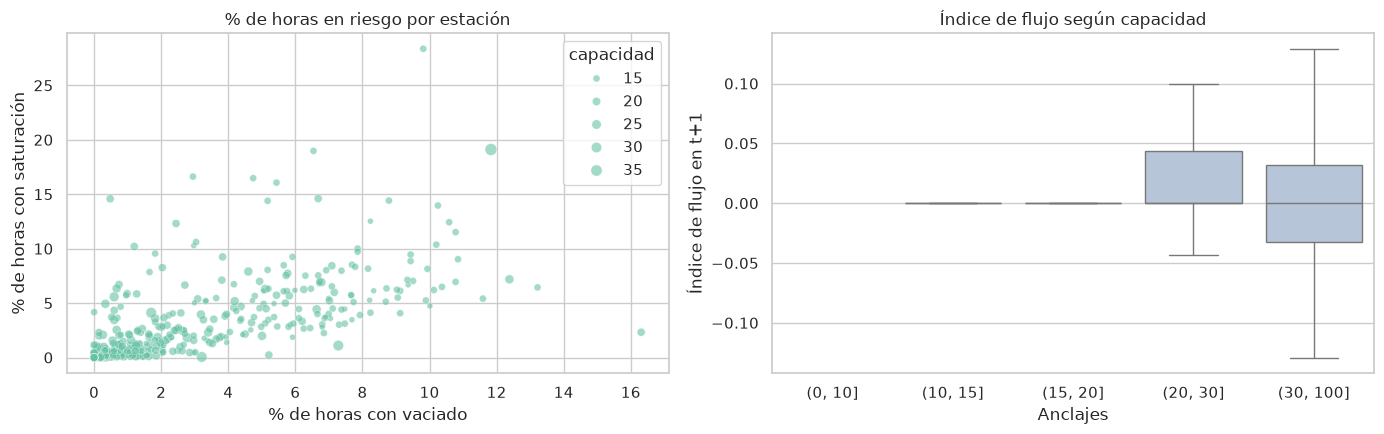

Estaciones que nunca tienen riesgo: 22 de 411


,vaciado,saturacion,capacidad
estacion,,,
194,16.31,2.32,19
199,13.22,6.44,15
11,12.38,7.18,23
51,11.83,19.11,39
197,11.59,5.41,15


In [15]:
riesgo = (p2.assign(vaciado=p2["y_riesgo_t1"] == "vaciado", saturacion=p2["y_riesgo_t1"] == "saturacion")
            .groupby("estacion")[["vaciado", "saturacion"]].mean().mul(100))
riesgo["capacidad"] = cat.set_index("estacion_id").loc[riesgo.index, "capacidad"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.scatterplot(data=riesgo, x="vaciado", y="saturacion", size="capacidad", alpha=0.6, ax=axes[0])
axes[0].set(title="% de horas en riesgo por estación", xlabel="% de horas con vaciado", ylabel="% de horas con saturación")
sns.boxplot(data=p2.assign(capacidad=pd.cut(p2["capacidad"], [0, 10, 15, 20, 30, 100])),
            x="capacidad", y="indice_flujo_t1", ax=axes[1], showfliers=False, color="lightsteelblue")
axes[1].set(title="Índice de flujo según capacidad", xlabel="Anclajes", ylabel="Índice de flujo en t+1")
plt.tight_layout()
plt.show()
print(f"Estaciones que nunca tienen riesgo: {(riesgo[['vaciado', 'saturacion']].sum(axis=1) == 0).sum()} de {len(riesgo)}")
display(riesgo.sort_values("vaciado", ascending=False).head(5).round(2))

Las estaciones de menor capacidad llegan al umbral con menos viajes, porque el índice divide entre los anclajes. Conviene evaluar el modelo **por segmento** (capacidad, estaciones nuevas) y no solo en promedio.

### Paso 5: P3. Perfiles de estación

Estaciones con perfil: 369 (solo periodo de entrenamiento, ene-abr)


,count,mean,std,min,25%,50%,75%,max
horas_operando,369.0,2875.382,80.004,1344.000,2880.000,2880.000,2880.000,2880.000
movimientos_totales,369.0,7436.710,7253.223,563.000,2638.000,5635.000,9718.000,56937.000
prom_salidas_hora,369.0,1.293,1.238,0.120,0.475,0.977,1.665,9.078
prom_llegadas_hora,369.0,1.293,1.299,0.065,0.426,0.973,1.689,10.711
balance_neto,369.0,-0.029,0.122,-0.408,-0.113,-0.032,0.030,0.402
prop_pico_am,369.0,0.133,0.037,0.041,0.107,0.130,0.156,0.256
prop_pico_pm,369.0,0.232,0.044,0.114,0.205,0.234,0.259,0.411
prop_fin_de_semana,369.0,0.210,0.058,0.069,0.179,0.203,0.228,0.500


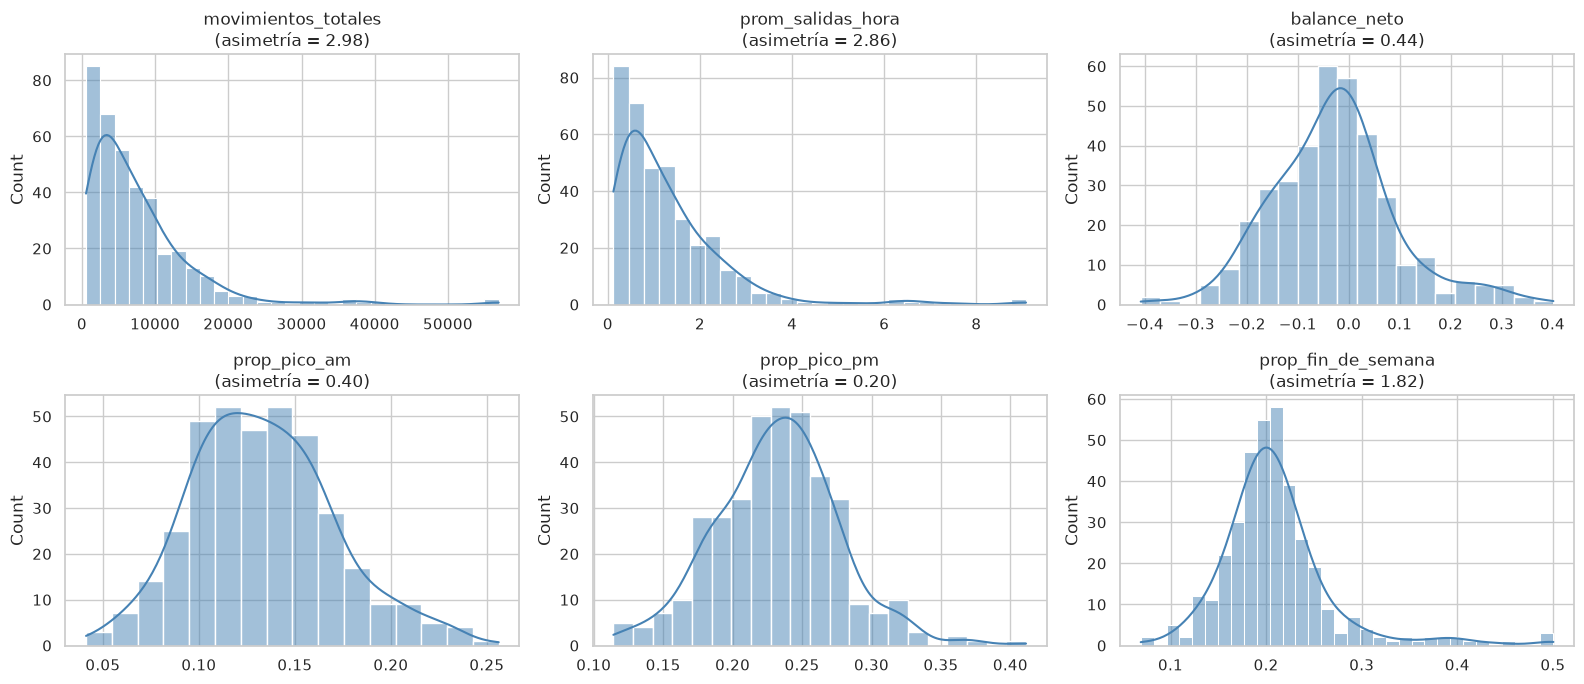

In [16]:
print(f"Estaciones con perfil: {len(p3)} (solo periodo de entrenamiento, ene-abr)")
display(p3.drop(columns="estacion").describe().T.round(3))

cols = ["movimientos_totales", "prom_salidas_hora", "balance_neto", "prop_pico_am", "prop_pico_pm", "prop_fin_de_semana"]
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, col in zip(axes.flatten(), cols):
    sns.histplot(p3[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(f"{col}\n(asimetría = {p3[col].skew():.2f})")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

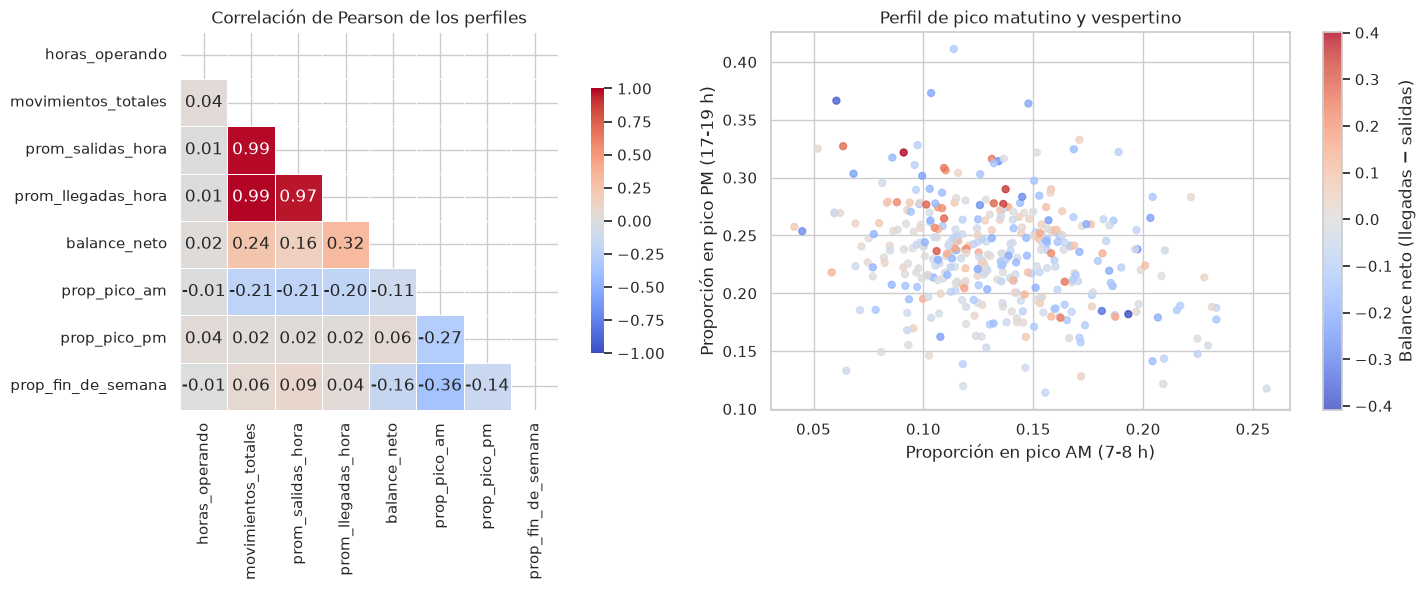

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
corr3 = p3.drop(columns="estacion").corr()
sns.heatmap(corr3, mask=np.triu(np.ones_like(corr3, dtype=bool)), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5, cbar_kws={"shrink": 0.7}, ax=axes[0])
axes[0].set_title("Correlación de Pearson de los perfiles")
sc = axes[1].scatter(p3["prop_pico_am"], p3["prop_pico_pm"], c=p3["balance_neto"], cmap="coolwarm", s=25, alpha=0.8)
plt.colorbar(sc, ax=axes[1], label="Balance neto (llegadas − salidas)")
axes[1].set(title="Perfil de pico matutino y vespertino", xlabel="Proporción en pico AM (7-8 h)", ylabel="Proporción en pico PM (17-19 h)")
plt.tight_layout()
plt.show()

Las variables de P3 tienen escalas muy distintas (`movimientos_totales` en miles y las proporciones entre 0 y 1) y asimetría fuerte en el volumen. Antes de aplicar K-Means hay que **estandarizar** y probablemente transformar el volumen con logaritmo.

### Paso 6: Arranque en frío y fuga de información

In [18]:
entr_est = set(p1.loc[p1["conjunto"] == "entrenamiento", "estacion"])
prueba = p1[p1["conjunto"] == "prueba"].copy()
prueba["estacion_nueva"] = ~prueba["estacion"].isin(entr_est)
n_nuevas = prueba.loc[prueba["estacion_nueva"], "estacion"].nunique()
display(prueba.groupby("estacion_nueva").agg(
    estaciones=("estacion", "nunique"), filas=("estacion", "size"), salidas_promedio=("y_salidas_t1", "mean"),
).round(3).rename(index={False: "con historia en entrenamiento", True: "nueva (arranque en frío)"}))
print(f"El conjunto de prueba incluye {n_nuevas} estaciones sin historia en entrenamiento: se reportan por separado.")

,estaciones,filas,salidas_promedio
estacion_nueva,,,
con historia en entrenamiento,368,264000,1.233
nueva (arranque en frío),42,15312,0.542


El conjunto de prueba incluye 42 estaciones sin historia en entrenamiento: se reportan por separado.


In [19]:
from mibici_mlops_module.features import validar_sin_fuga

validar_sin_fuga(viajes, p1)
print("Objetivos y rezagos recalculados desde los viajes: correctos. Sin valores nulos.")

Objetivos y rezagos recalculados desde los viajes: correctos. Sin valores nulos.


La comprobación recalcula, para una muestra de 2,000 filas, que `y_salidas_t1` sean exactamente las salidas de la hora siguiente y que los rezagos sean salidas del pasado. Las variables de calendario se calculan sobre la hora objetivo, que se conoce de antemano.

### Paso 7: Hallazgos del análisis exploratorio

**Calidad y limpieza**

* 2,090,228 viajes crudos y 2,012,763 limpios (96.3 %). Sin duplicados ni nulos.
* Se descartan 75,295 viajes de menos de 1 minuto (3.6 %), 249 de más de 3 horas y 1,921 de las estaciones 405 y 407, que no están en la nomenclatura.
* Duración típica: mediana de 9.9 min y percentil 99 de 34 min.

**Estaciones y red**

* 426 estaciones válidas con capacidad de 11 a 39 anclajes (mediana 15).
* El 20 % de las estaciones concentra el 52.1 % de los movimientos.
* La red creció: 12 estaciones abrieron en mayo, 45 en junio y 1 en marzo. Las estaciones 34 y 35 dejaron de registrar viajes el 24 de mayo y el 11 de junio. Por eso se usa una ventana de operación por estación.

**P1. Demanda**

* 1.55 millones de filas (411 estaciones). Partición temporal: 999,024 para entrenamiento, 274,512 para validación y 279,312 para prueba.
* El objetivo es un conteo sobredisperso: media 1.25, varianza 5.66, asimetría 6.0, **54.8 % de ceros** y máximo de 147.
* Baselines en validación: el estacional semanal (t−167) es el mejor, con MAE 0.891 y RMSE 1.759. Persistencia: MAE 0.969. Media global: MAE 1.390. Un modelo debe superar 0.891.

**P2. Riesgo**

* Con u = 0.20 los umbrales coinciden con los percentiles 2.5 y 97.5 del índice (−0.200 y +0.211).
* Entrenamiento: 3.49 % vaciado, 93.01 % normal y 3.51 % saturación. Las clases raras bajan en validación (2.86 % y 2.91 %) y en prueba (2.76 % y 2.83 %). El desbalance cambia en el tiempo.
* Predecir siempre "normal" da más de 93 % de exactitud, por eso se evalúa con recall por clase, balanced accuracy y F1 macro.
* 22 de 411 estaciones nunca llegan al umbral de riesgo, mientras que otras lo hacen más del 10 % de las horas.

**P3. Perfiles**

* 369 estaciones con perfil (solo entrenamiento). El volumen varía mucho: de 563 a 56,937 movimientos (mediana 5,635), mientras que las proporciones de pico y de fin de semana están entre 0 y 1. Hay que estandarizar antes de K-Means.

**Arranque en frío y fuga**

* La prueba incluye 42 estaciones sin historia en entrenamiento, con 0.54 salidas por hora frente a 1.23 en las demás. Se reportan por separado.
* La validación anti-fuga pasa: objetivos y rezagos coinciden con el cálculo directo desde los viajes.